In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt




In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/balance_dataset"

total_images = 0

for class_name in os.listdir(DATASET_PATH):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        image_count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])

        print(f"{class_name} → {image_count} images")
        total_images += image_count

print("=================================")
print(f"Total Images: {total_images}")

sandy_soil → 1000 images
yellow_soil → 1000 images
red_soil → 997 images
peat_soil → 1000 images
black_soil → 1000 images
loamy_soil → 999 images
alluvial_soil → 996 images
clay_soil → 999 images
Total Images: 7991


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/split_dataset/train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_data = val_datagen.flow_from_directory(
    "/content/drive/MyDrive/split_dataset/val",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)
test_data = test_datagen.flow_from_directory(
    "/content/drive/MyDrive/split_dataset/test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

num_classes = train_data.num_classes


Found 5592 images belonging to 8 classes.
Found 1199 images belonging to 8 classes.
Found 1200 images belonging to 8 classes.


In [ ]:
print(train_data.class_indices)

{'alluvial_soil': 0, 'black_soil': 1, 'clay_soil': 2, 'loamy_soil': 3, 'peat_soil': 4, 'red_soil': 5, 'sandy_soil': 6, 'yellow_soil': 7}


In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False   # Freeze base CNN


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])


In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,976 (9.87 MB)

 Trainable params: 329,992 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

checkpoint = ModelCheckpoint("best_model.h5", monitor="val_accuracy", save_best_only=True, mode="max")
earlystop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, verbose=1)

history = model.fit(
    train_data,
    epochs=15,
    validation_data=val_data,
    callbacks=[checkpoint, earlystop, reduce_lr]
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
174/175 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - accuracy: 0.4765 - loss: 1.4914

175/175 ━━━━━━━━━━━━━━━━━━━━ 2233s 13s/step - accuracy: 0.4786 - loss: 1.4862 - val_accuracy: 0.8307 - val_loss: 0.5458 - learning_rate: 1.0000e-04
Epoch 2/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step - accuracy: 0.8247 - loss: 0.5473

175/175 ━━━━━━━━━━━━━━━━━━━━ 88s 502ms/step - accuracy: 0.8248 - loss: 0.5470 - val_accuracy: 0.8891 - val_loss: 0.3705 - learning_rate: 1.0000e-04
Epoch 3/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.8739 - loss: 0.3883

175/175 ━━━━━━━━━━━━━━━━━━━━ 93s 534ms/step - accuracy: 0.8739 - loss: 0.3883 - val_accuracy: 0.9158 - val_loss: 0.2951 - learning_rate: 1.0000e-04
Epoch 4/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.8900 - loss: 0.3309

175/175 ━━━━━━━━━━━━━━━━━━━━ 89s 507ms/step - accuracy: 0.8900 - loss: 0.3308 - val_accuracy: 0.9216 - val_loss: 0.2538 - learning_rate: 1.0000e-04
Epoch 5/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 87s 499ms/step - accuracy: 0.9177 - loss: 0.2615 - val_accuracy: 0.9166 - val_loss: 0.2491 - learning_rate: 1.0000e-04
Epoch 6/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.9165 - loss: 0.2599

175/175 ━━━━━━━━━━━━━━━━━━━━ 88s 502ms/step - accuracy: 0.9165 - loss: 0.2598 - val_accuracy: 0.9399 - val_loss: 0.2021 - learning_rate: 1.0000e-04
Epoch 7/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 92s 528ms/step - accuracy: 0.9331 - loss: 0.2103 - val_accuracy: 0.9374 - val_loss: 0.1915 - learning_rate: 1.0000e-04
Epoch 8/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.9391 - loss: 0.1956

175/175 ━━━━━━━━━━━━━━━━━━━━ 92s 525ms/step - accuracy: 0.9391 - loss: 0.1956 - val_accuracy: 0.9475 - val_loss: 0.1729 - learning_rate: 1.0000e-04
Epoch 9/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.9434 - loss: 0.1784

175/175 ━━━━━━━━━━━━━━━━━━━━ 89s 506ms/step - accuracy: 0.9434 - loss: 0.1784 - val_accuracy: 0.9491 - val_loss: 0.1714 - learning_rate: 1.0000e-04
Epoch 10/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.9510 - loss: 0.1657

175/175 ━━━━━━━━━━━━━━━━━━━━ 87s 494ms/step - accuracy: 0.9510 - loss: 0.1657 - val_accuracy: 0.9575 - val_loss: 0.1517 - learning_rate: 1.0000e-04
Epoch 11/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 87s 495ms/step - accuracy: 0.9548 - loss: 0.1471 - val_accuracy: 0.9566 - val_loss: 0.1452 - learning_rate: 1.0000e-04
Epoch 12/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 86s 494ms/step - accuracy: 0.9570 - loss: 0.1484 - val_accuracy: 0.9566 - val_loss: 0.1444 - learning_rate: 1.0000e-04
Epoch 13/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.9590 - loss: 0.1351

175/175 ━━━━━━━━━━━━━━━━━━━━ 87s 497ms/step - accuracy: 0.9590 - loss: 0.1351 - val_accuracy: 0.9633 - val_loss: 0.1303 - learning_rate: 1.0000e-04
Epoch 14/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 86s 489ms/step - accuracy: 0.9621 - loss: 0.1270 - val_accuracy: 0.9625 - val_loss: 0.1196 - learning_rate: 1.0000e-04
Epoch 15/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 86s 494ms/step - accuracy: 0.9630 - loss: 0.1200 - val_accuracy: 0.9608 - val_loss: 0.1377 - learning_rate: 1.0000e-04


In [ ]:
# Unfreeze last 30 layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data,
    callbacks=[checkpoint, earlystop, reduce_lr]
)


Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 123s 607ms/step - accuracy: 0.7747 - loss: 0.6340 - val_accuracy: 0.9475 - val_loss: 0.1517 - learning_rate: 1.0000e-05
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 90s 513ms/step - accuracy: 0.8906 - loss: 0.3077 - val_accuracy: 0.9516 - val_loss: 0.1542 - learning_rate: 1.0000e-05
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 90s 512ms/step - accuracy: 0.9245 - loss: 0.2389 - val_accuracy: 0.9500 - val_loss: 0.1506 - learning_rate: 1.0000e-05
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 88s 504ms/step - accuracy: 0.9378 - loss: 0.2094 - val_accuracy: 0.9508 - val_loss: 0.1378 - learning_rate: 1.0000e-05
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 88s 504ms/step - accuracy: 0.9501 - loss: 0.1623 - val_accuracy: 0.9466 - val_loss: 0.1363 - learning_rate: 1.0000e-05
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 89s 507ms/step - accuracy: 0.9455 - loss: 0.1709 - val_accuracy: 0.9558 - val_loss: 0.1234 - learning_rate: 1.0000e-05
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 89s 5

175/175 ━━━━━━━━━━━━━━━━━━━━ 90s 515ms/step - accuracy: 0.9594 - loss: 0.1251 - val_accuracy: 0.9650 - val_loss: 0.1017 - learning_rate: 1.0000e-05
Epoch 10/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 90s 516ms/step - accuracy: 0.9661 - loss: 0.1032 - val_accuracy: 0.9641 - val_loss: 0.0978 - learning_rate: 1.0000e-05


In [ ]:
# -------------------------
# 1. Save for TF Serving
model.export("/content/drive/MyDrive/final_soil_mobilenetv2_tf_serving_model")
print("Model exported successfully for TF Serving ✅")
# 2. Save in Keras native format
model.save("/content/drive/MyDrive/final_soil_mobilenetv2_finetuned.keras")
print("Keras model saved ✅")

# 3. Optional HDF5 (old style)
model.save("/content/drive/MyDrive/final_soil_mobilenetv2_finetuned.h5")
print("HDF5 model saved ✅")
# -------------------------


Saved artifact at '/content/drive/MyDrive/final_soil_mobilenetv2_tf_serving_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  136027188830928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573315600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573318288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573317904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573316752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573318480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573316944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573319056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573318672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136024573316560: TensorSpec(shape=

Keras model saved ✅
HDF5 model saved ✅


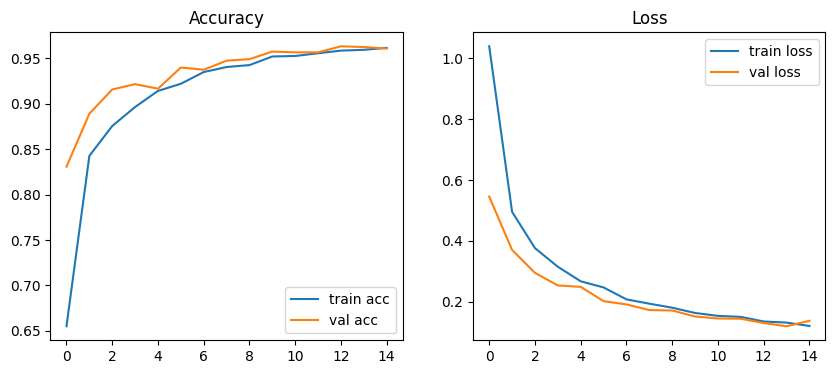

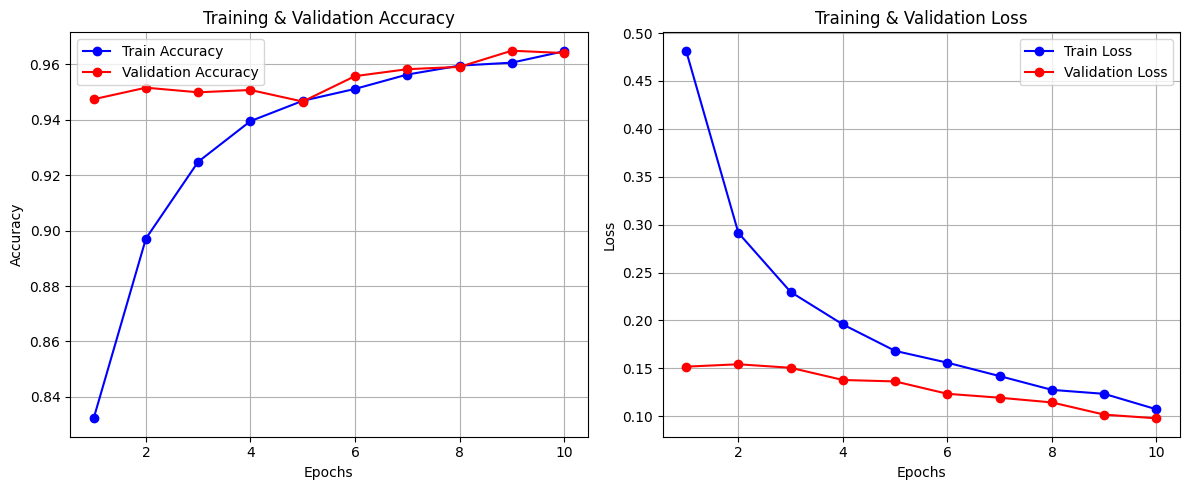

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title("Loss")
plt.show()



import matplotlib.pyplot as plt

# history_fine = fine-tuning ke model.fit() ka history object
# Agar aapne 'history' hi use kiya tha, uska naam daal do
acc = history_fine.history['accuracy']
val_acc = history_fine.history['val_accuracy']
loss = history_fine.history['loss']
val_loss = history_fine.history['val_loss']

epochs = range(1, len(acc) + 1)

# -------------------------
# Plot Accuracy
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(epochs, acc, 'b-o', label='Train Accuracy')
plt.plot(epochs, val_acc, 'r-o', label='Validation Accuracy')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1,2,2)
plt.plot(epochs, loss, 'b-o', label='Train Loss')
plt.plot(epochs, val_loss, 'r-o', label='Validation Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



38/38 ━━━━━━━━━━━━━━━━━━━━ 420s 11s/step


<Figure size 800x800 with 0 Axes>

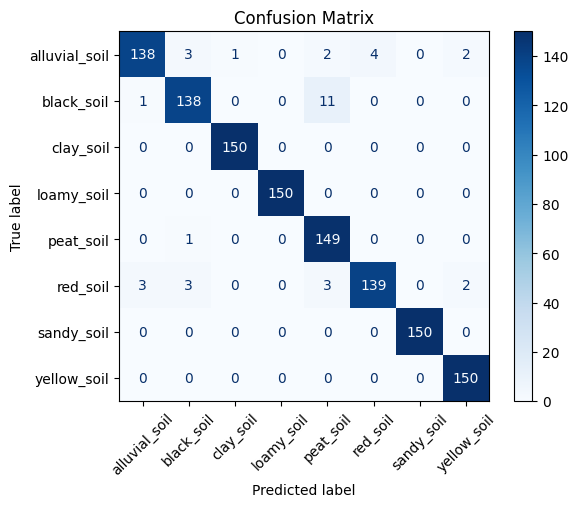

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# -------------------------
# Step 1: Model predictions on test data
y_pred_probs = model.predict(test_data, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)   # predicted class indices
y_true = test_data.classes                 # true class indices

class_names = list(test_data.class_indices.keys())  # class labels

# -------------------------
# Step 2: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.figure(figsize=(8,8))
disp.plot(cmap=plt.cm.Blues, values_format='d', xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()



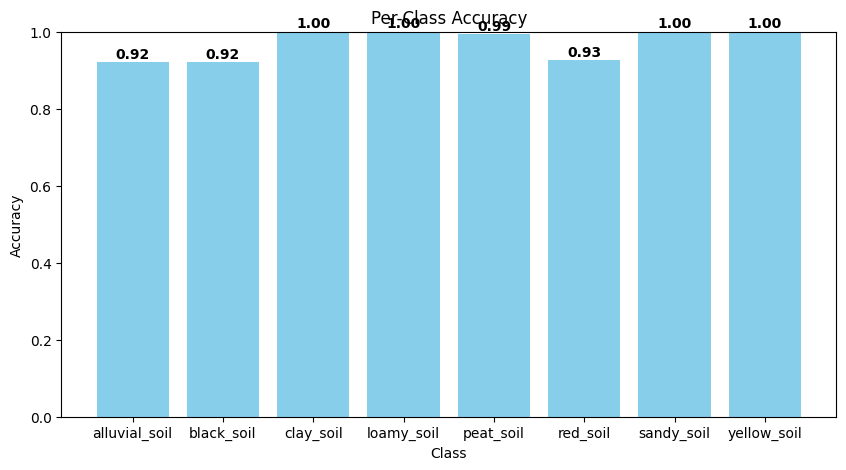

In [ ]:
# -------------------------
# Step 3: Per-Class Accuracy
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(10,5))
plt.bar(class_names, per_class_acc, color='skyblue')
plt.ylim(0,1)
plt.title("Per-Class Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Class")
for i, v in enumerate(per_class_acc):
    plt.text(i, v + 0.01, f"{v:.2f}", ha='center', fontweight='bold')
plt.show()


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

# -------------------------
# Step 1: Predict on test data
y_pred_probs = model.predict(test_data, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# True labels
y_true = test_data.classes

# Class names
class_names = list(test_data.class_indices.keys())

# -------------------------
# Step 2: Classification Report
print("\n📊 Classification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

# -------------------------
# Step 3: Test Accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print(f"\n✅ Test Accuracy: {test_accuracy*100:.2f}%")


38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 154ms/step

📊 Classification Report:

               precision    recall  f1-score   support

alluvial_soil     0.9718    0.9200    0.9452       150
   black_soil     0.9517    0.9200    0.9356       150
    clay_soil     0.9934    1.0000    0.9967       150
   loamy_soil     1.0000    1.0000    1.0000       150
    peat_soil     0.9030    0.9933    0.9460       150
     red_soil     0.9720    0.9267    0.9488       150
   sandy_soil     1.0000    1.0000    1.0000       150
  yellow_soil     0.9740    1.0000    0.9868       150

     accuracy                         0.9700      1200
    macro avg     0.9708    0.9700    0.9699      1200
 weighted avg     0.9708    0.9700    0.9699      1200


✅ Test Accuracy: 97.00%


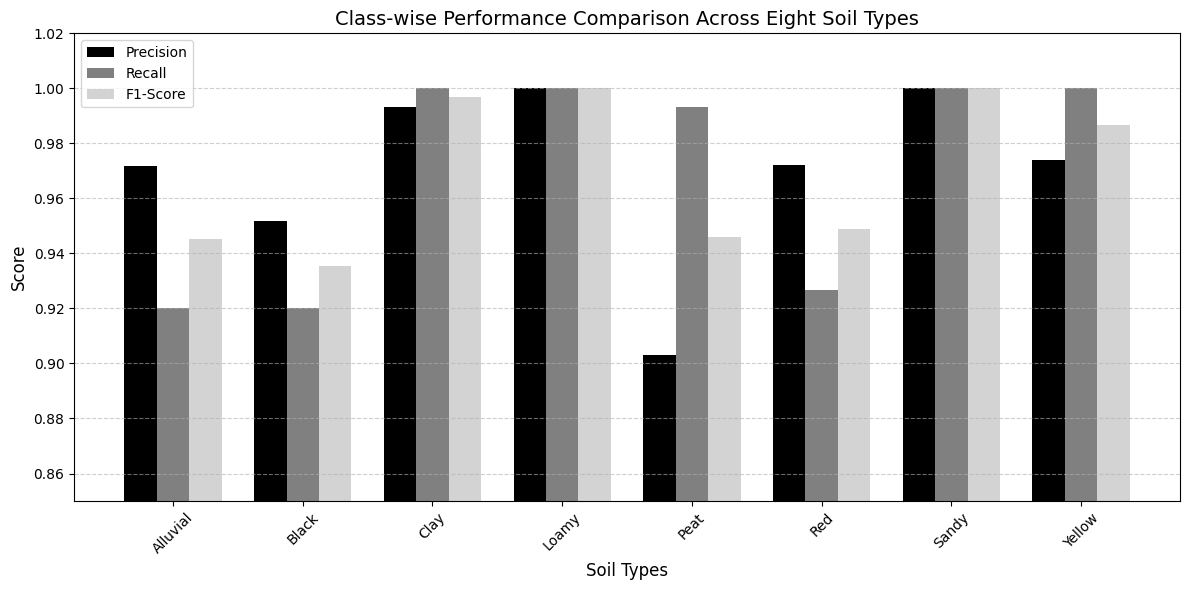

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Class names
classes = [
    'Alluvial', 'Black', 'Clay', 'Loamy',
    'Peat', 'Red', 'Sandy', 'Yellow'
]

# Metrics from your classification report
precision = [0.9718, 0.9517, 0.9934, 1.0000, 0.9030, 0.9720, 1.0000, 0.9740]
recall    = [0.9200, 0.9200, 1.0000, 1.0000, 0.9933, 0.9267, 1.0000, 1.0000]
f1_score  = [0.9452, 0.9356, 0.9967, 1.0000, 0.9460, 0.9488, 1.0000, 0.9868]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(12,6))

# Bar plots
plt.bar(x - width, precision, width, label='Precision', color='black')
plt.bar(x, recall, width, label='Recall', color='gray')
plt.bar(x + width, f1_score, width, label='F1-Score', color='lightgray')

# Labels and title
plt.xlabel('Soil Types', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.title('Class-wise Performance Comparison Across Eight Soil Types', fontsize=14)

plt.xticks(x, classes, rotation=45)
plt.ylim(0.85, 1.02)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


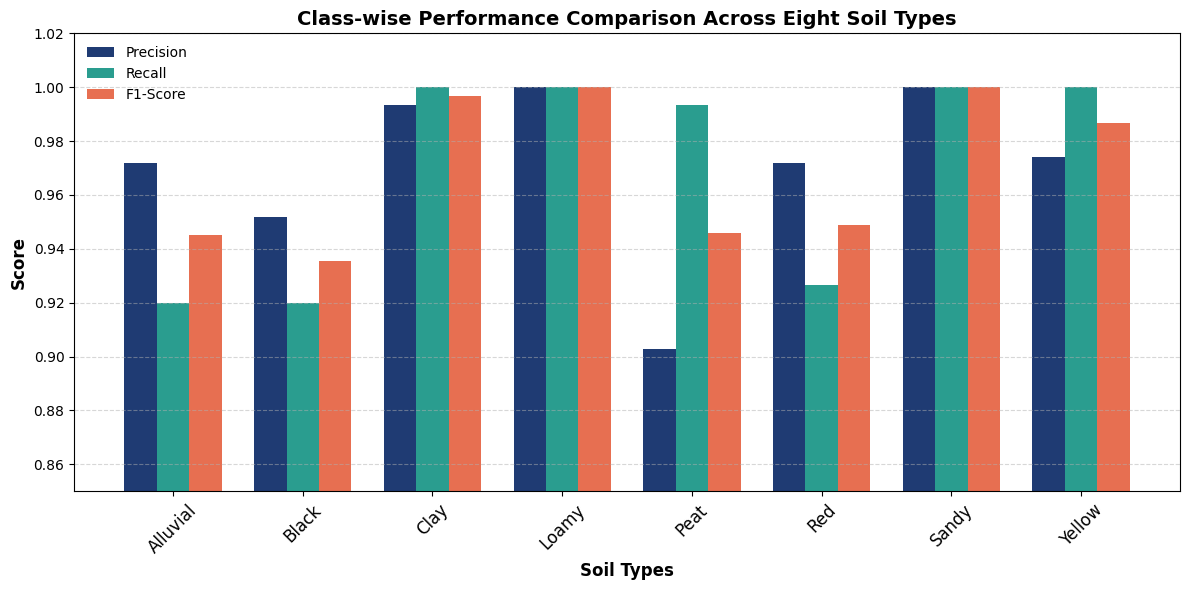

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Class names
classes = [
    'Alluvial', 'Black', 'Clay', 'Loamy',
    'Peat', 'Red', 'Sandy', 'Yellow'
]

# Metrics
precision = [0.9718, 0.9517, 0.9934, 1.0000, 0.9030, 0.9720, 1.0000, 0.9740]
recall    = [0.9200, 0.9200, 1.0000, 1.0000, 0.9933, 0.9267, 1.0000, 1.0000]
f1_score  = [0.9452, 0.9356, 0.9967, 1.0000, 0.9460, 0.9488, 1.0000, 0.9868]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(12,6))

# Professional academic colors
precision_color = '#1f3b73'   # Deep Blue
recall_color    = '#2a9d8f'   # Teal Green
f1_color        = '#e76f51'   # Soft Orange

plt.bar(x - width, precision, width, label='Precision', color=precision_color)
plt.bar(x, recall, width, label='Recall', color=recall_color)
plt.bar(x + width, f1_score, width, label='F1-Score', color=f1_color)

plt.xlabel('Soil Types', fontsize=12, fontweight='bold')
plt.ylabel('Score', fontsize=12, fontweight='bold')
plt.title('Class-wise Performance Comparison Across Eight Soil Types',
          fontsize=14, fontweight='bold')

plt.xticks(x, classes, rotation=45,fontsize=12)
plt.ylim(0.85, 1.02)

plt.legend(frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# High resolution for paper
plt.savefig("class_wise_performance.png", dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
num_classes = train_data.num_classes
print(num_classes)

5


In [ ]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Crop_recommendation.csv")

print(df.head())
print(df.info())
print(df.describe())

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB
None
         

In [ ]:
X = df.drop(columns=["label"])
y = df["label"]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:
model.fit(X_train, y_train)
print("✅ Model trained successfully")


✅ Model trained successfully


In [ ]:
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))


✅ Accuracy: 0.9955


In [ ]:
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))



=== Classification Report ===
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00       

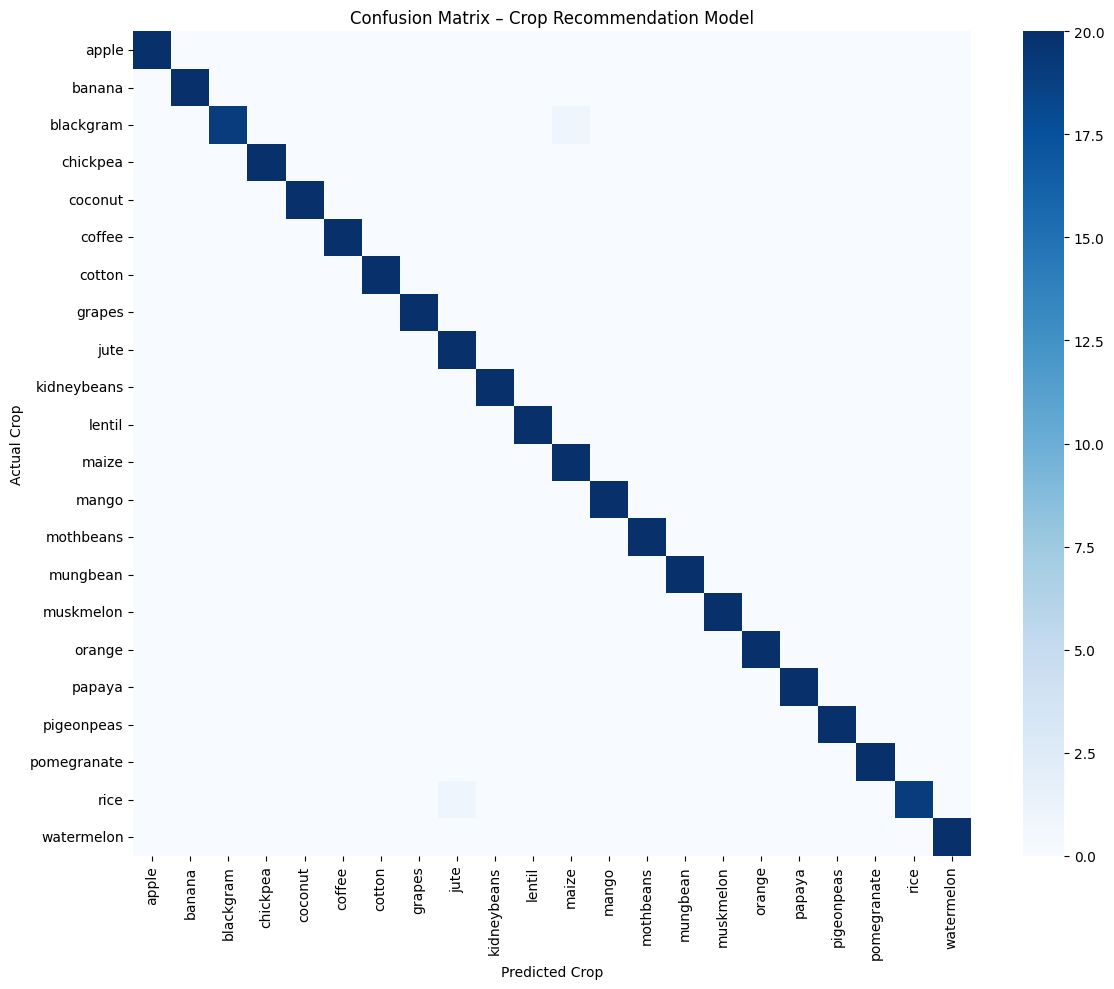

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(12,10))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    annot=False
)
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.title("Confusion Matrix – Crop Recommendation Model")
plt.tight_layout()
plt.show()


In [ ]:
joblib.dump(model, "/content/drive/MyDrive/crop_recommendation_model.pkl")
print("💾 Model saved as crop_recommendation_model.pkl")


💾 Model saved as crop_recommendation_model.pkl


In [ ]:
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
from tensorflow.keras.preprocessing import image


In [ ]:
soil_crop_map = {
    "alluvial_soil": ["rice", "wheat", "sugarcane", "maize"],
    "black_soil": ["cotton", "soybean", "groundnut"],
    "clay_soil": ["rice", "wheat"],
    "loamy_soil": ["wheat", "maize", "vegetables", "pulses"],
    "peat_soil": ["potato", "carrot"],
    "red_soil": ["millets", "pulses", "groundnut"],
    "sandy_soil": ["peanut", "watermelon"],
    "yellow_soil": ["rice", "potato"]
}


In [ ]:
def check_soil_suitability(soil_type, crop):
    suitable_crops = soil_crop_map.get(soil_type, [])

    if crop.lower() in suitable_crops:
        return "Highly Suitable"
    else:
        return "Moderately Suitable"


In [ ]:
def get_warning_message(suitability, soil_type, crop):
    if suitability == "Highly Suitable":
        return "✅ The recommended crop is well suited for the predicted soil type."
    else:
        return (
            f"⚠️ Warning: The recommended crop '{crop}' is not ideally suited for "
            f"{soil_type.replace('_', ' ')}. Soil improvement or alternative crops may be considered."
        )


In [ ]:
def suggest_alternative_crops(soil_type, exclude_crop):
    alternatives = soil_crop_map.get(soil_type, [])

    # Remove already recommended crop if present
    alternatives = [c for c in alternatives if c.lower() != exclude_crop.lower()]

    # Return max 3 suggestions
    return alternatives[:3]


In [ ]:
# Load soil CNN model
soil_model = tf.keras.models.load_model("/content/drive/MyDrive/final_soil_mobilenetv2_finetuned.keras")

# Load crop ML model
crop_model = joblib.load("/content/drive/MyDrive/crop_recommendation_model.pkl")

print("✅ Models loaded successfully")


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 38 variables whereas the saved optimizer has 74 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


✅ Models loaded successfully


In [ ]:
SOIL_CLASSES = ['alluvial_soil', 'black_soil', 'clay_soil', 'loamy_soil',
                'peat_soil', 'red_soil', 'sandy_soil', 'yellow_soil']


In [ ]:
def predict_soil_type(image_path):
    img = image.load_img(image_path, target_size=(224, 224))
    img = image.img_to_array(img) / 255.0
    img = np.expand_dims(img, axis=0)

    preds = soil_model.predict(img)
    idx = np.argmax(preds)
    confidence = preds[0][idx] * 100

    return {
        "soil_type": SOIL_CLASSES[idx],
        "confidence": round(confidence, 2)
    }


In [ ]:
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    X_input = pd.DataFrame([{
        "N": N,
        "P": P,
        "K": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }])

    crop = crop_model.predict(X_input)[0]
    prob = max(crop_model.predict_proba(X_input)[0]) * 100

    return {
        "crop": crop,
        "confidence": round(prob, 2)
    }


In [ ]:
def full_pipeline(
    image_path,
    N, P, K,
    temperature,
    humidity,
    ph,
    rainfall
):
    print("📸 Processing soil image...")
    soil_result = predict_soil_type(image_path)

    soil_type = soil_result["soil_type"]
    print("🌱 Soil Type:", soil_type)
    print("🎯 Soil Confidence:", soil_result["confidence"], "%")

    print("\n🌾 Recommending crop...")
    crop_result = recommend_crop(
        N, P, K,
        temperature,
        humidity,
        ph,
        rainfall
    )

    crop_name = crop_result["crop"]
    print("🌾 Crop:", crop_name)
    print("🎯 Crop Confidence:", crop_result["confidence"], "%")

    # ✅ Suitability Check
    suitability = check_soil_suitability(soil_type, crop_name)
    print("\n✅ Soil–Crop Suitability:", suitability)

    # ⚠️ Warning Message
    warning_msg = get_warning_message(suitability, soil_type, crop_name)
    print(warning_msg)

    # 🔁 Alternative Crops (only if mismatch)
    alternatives = []
    if suitability != "Highly Suitable":
        alternatives = suggest_alternative_crops(soil_type, crop_name)
        print("🔁 Alternative crops for this soil:", alternatives)

    return {
        "Predicted Soil": soil_result,
        "Recommended Crop": crop_result,
        "Suitability Status": suitability,
        "Warning": warning_msg,
        "Alternative Crops": alternatives
    }


In [ ]:
result = full_pipeline(
    image_path="/content/drive/MyDrive/split_dataset/test/loamy_soil/IMG_20250110_153503_1_jpg.rf.982383a7d5bfa0c5ecf047c3eb4e893e.jpg",   # ← soil image
    N=32,
    P=70,
    K=20,
    temperature=20.89342749,
    humidity=46.24856523,
    ph=6.208843215,
    rainfall=195.5697875
)

print("\n✅ FINAL OUTPUT")
print(result)


📸 Processing soil image...
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
🌱 Soil Type: loamy_soil
🎯 Soil Confidence: 100.0 %

🌾 Recommending crop...
🌾 Crop: pigeonpeas
🎯 Crop Confidence: 97.8 %

✅ Soil–Crop Suitability: Moderately Suitable
⚠️ Warning: The recommended crop 'pigeonpeas' is not ideally suited for loamy soil. Soil improvement or alternative crops may be considered.
🔁 Alternative crops for this soil: ['wheat', 'maize', 'vegetables']

✅ FINAL OUTPUT
{'Predicted Soil': {'soil_type': 'loamy_soil', 'confidence': np.float32(100.0)}, 'Recommended Crop': {'crop': 'pigeonpeas', 'confidence': np.float64(97.8)}, 'Suitability Status': 'Moderately Suitable', 'Warning': "⚠️ Warning: The recommended crop 'pigeonpeas' is not ideally suited for loamy soil. Soil improvement or alternative crops may be considered.", 'Alternative Crops': ['wheat', 'maize', 'vegetables']}


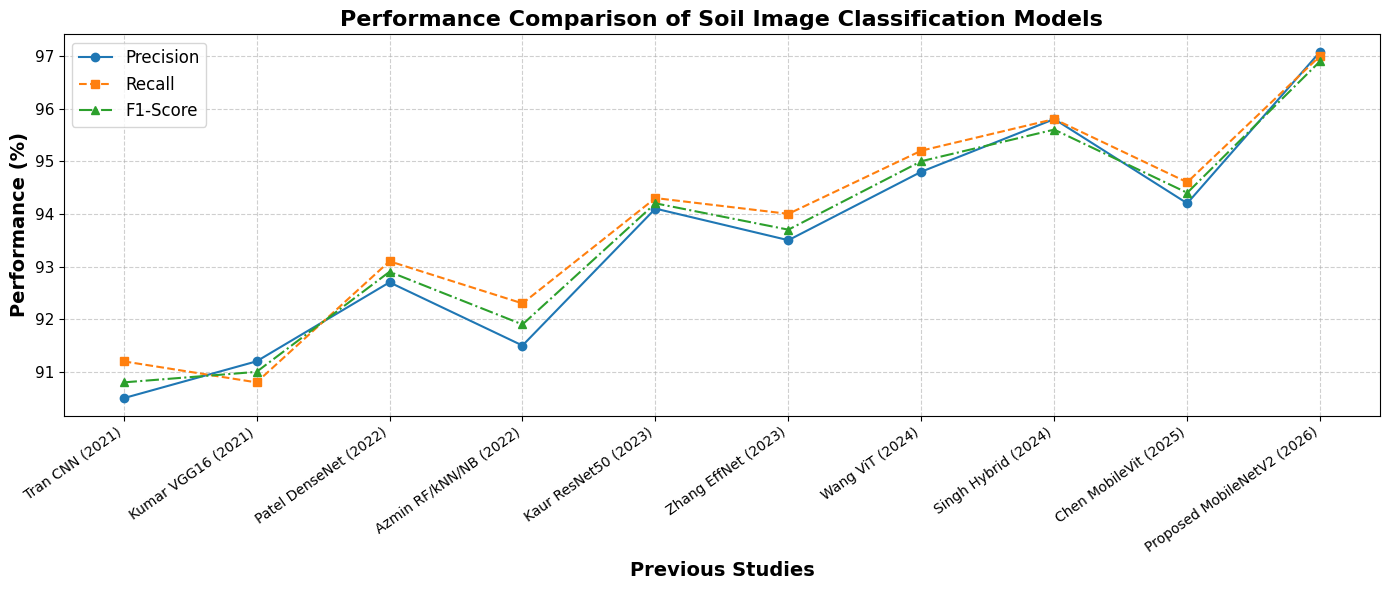

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Study labels (short & clean for paper figure)
studies = [
    "Tran CNN (2021)",
    "Kumar VGG16 (2021)",
    "Patel DenseNet (2022)",
    "Azmin RF/kNN/NB (2022)",
    "Kaur ResNet50 (2023)",
    "Zhang EffNet (2023)",
    "Wang ViT (2024)",
    "Singh Hybrid (2024)",
    "Chen MobileVit (2025)",
    "Proposed MobileNetV2 (2026)"
]

# Performance values from your table
precision = [90.5, 91.2, 92.7, 91.5, 94.1, 93.5, 94.8, 95.8, 94.2, 97.08]
recall    = [91.2, 90.8, 93.1, 92.3, 94.3, 94.0, 95.2, 95.8, 94.6, 97.00]
f1_score  = [90.8, 91.0, 92.9, 91.9, 94.2, 93.7, 95.0, 95.6, 94.4, 96.9]

# X-axis positions
x = np.arange(len(studies))

# Create figure
plt.figure(figsize=(14, 6))

# Line plots (IEEE-style)
plt.plot(x, precision, marker='o', linestyle='-', label="Precision")
plt.plot(x, recall, marker='s', linestyle='--', label="Recall")
plt.plot(x, f1_score, marker='^', linestyle='-.', label="F1-Score")

# Labels & title
plt.xlabel("Previous Studies", fontsize=14, fontweight='bold')
plt.ylabel("Performance (%)", fontsize=14, fontweight='bold')
plt.title(
    "Performance Comparison of Soil Image Classification Models",
    fontsize=16,
    fontweight='bold'
)

# X-axis formatting
plt.xticks(x, studies, rotation=35, ha="right", fontsize=10)
plt.yticks(fontsize=11)

# Grid & legend
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Layout adjustment
plt.tight_layout()

# Save high-quality image
plt.savefig("soil_model_comparison_2021_2026.png", dpi=300, bbox_inches="tight")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
✅ Prediction Result
----------------------
Class: alluvial_soil
Confidence: 99.22 %


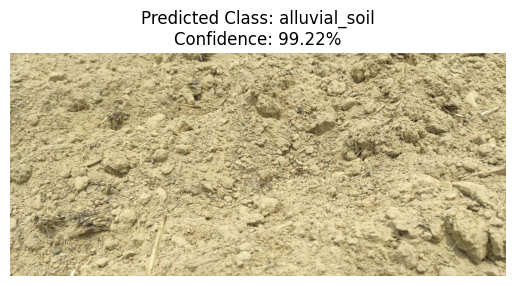

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Load the saved best weights model
model = tf.keras.models.load_model("/content/drive/MyDrive/my_model.keras")
# Class Names (Update this!)
class_names = ['alluvial_soil', 'black_soil', 'clay_soil', 'loamy_soil', 'peat_soil', 'red_soil',
               'sandy_soil', 'yellow_soil']  # <-- Update this list

# Image path
img_path = "/content/drive/MyDrive/split_dataset/test/alluvial_soil/115.jpg"

# Load image
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Prediction
pred = model.predict(img_array)
predicted_class = class_names[np.argmax(pred)]
confidence = np.max(pred) * 100

print("✅ Prediction Result")
print("----------------------")
print("Class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

#Display image with prediction
plt.imshow(image.load_img(img_path))
plt.title(f"Predicted Class: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.axis('off')
plt.show()


✅ Total Test Images Found: 1200
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


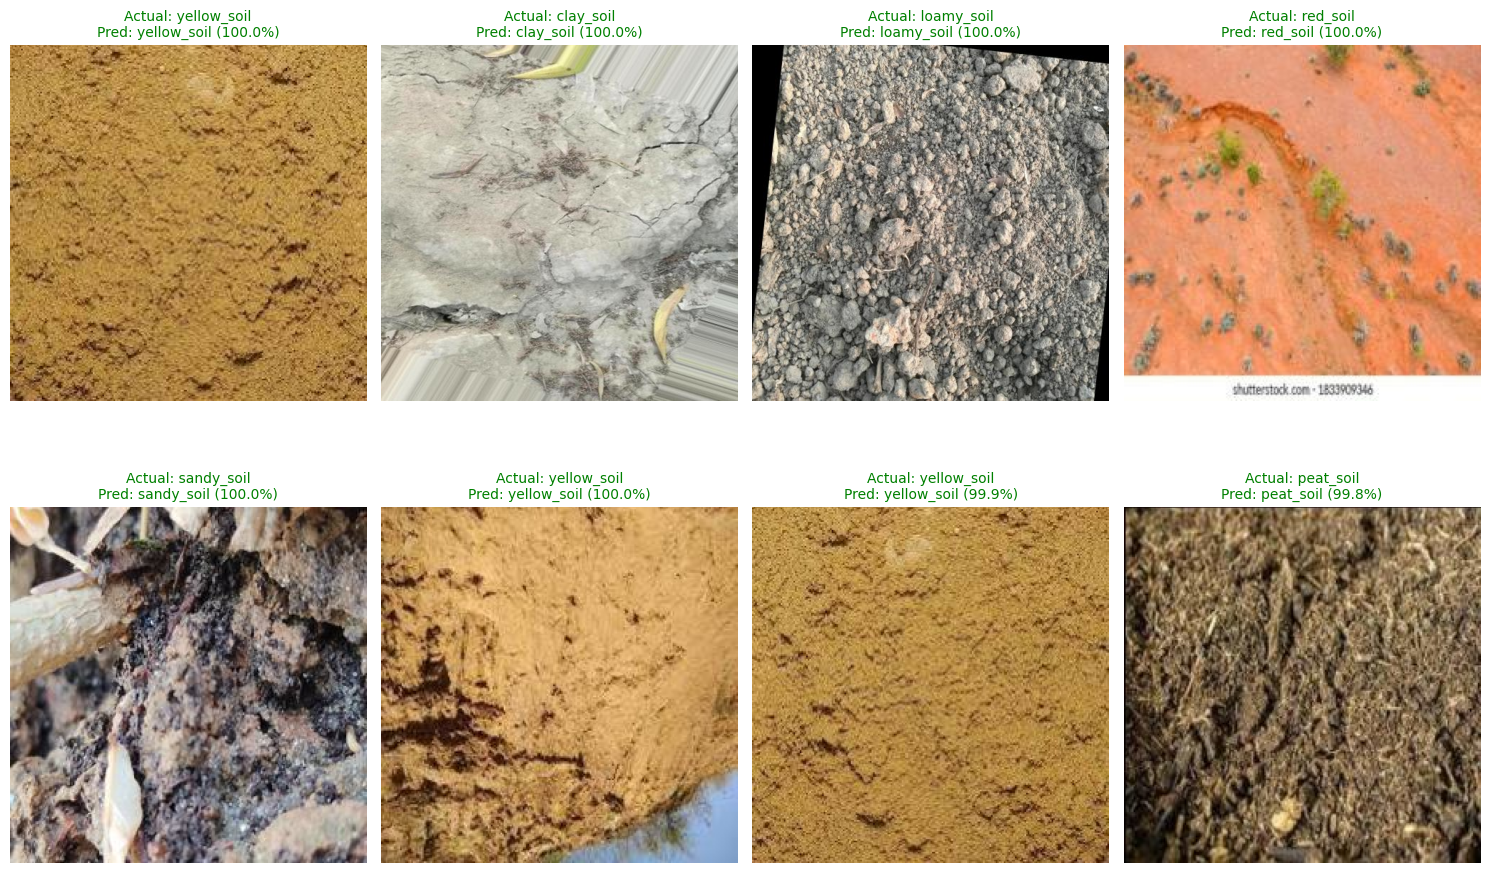

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# 1️⃣ Load trained model
model = load_model('/content/drive/MyDrive/final_soil_mobilenetv2_finetuned.keras')

# 2️⃣ Test dataset path
test_dir = '/content/drive/MyDrive/split_dataset/test'

# 3️⃣ Classes (same order used in training)
class_labels = ['alluvial_soil', 'black_soil', 'clay_soil', 'loamy_soil',
                'peat_soil', 'red_soil', 'sandy_soil', 'yellow_soil']

# 4️⃣ Collect test images and their true labels
test_images = []
test_labels = []

for label in class_labels:
    folder = os.path.join(test_dir, label)
    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.png', '.jpeg')):
            test_images.append(os.path.join(folder, fname))
            test_labels.append(label)

print(f"✅ Total Test Images Found: {len(test_images)}")

# 5️⃣ Function to preprocess image
def preprocess_img(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0
    return img_array

# 6️⃣ Predict on few random images
num_samples = 8  # number of test images to visualize
indices = np.random.choice(len(test_images), num_samples, replace=False)

plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices):
    img_path = test_images[idx]
    true_label = test_labels[idx]

    # Preprocess & predict
    img_array = preprocess_img(img_path)
    preds = model.predict(img_array)
    pred_label = class_labels[np.argmax(preds[0])]
    confidence = np.max(preds[0]) * 100

    # Plot image
    plt.subplot(2, 4, i+1)
    plt.imshow(image.load_img(img_path))
    plt.axis('off')

    # Title color: green if correct, red if wrong
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Actual: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
              color=color, fontsize=10)

plt.tight_layout()
plt.show()

✅ Total Unseen Images Found: 14
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


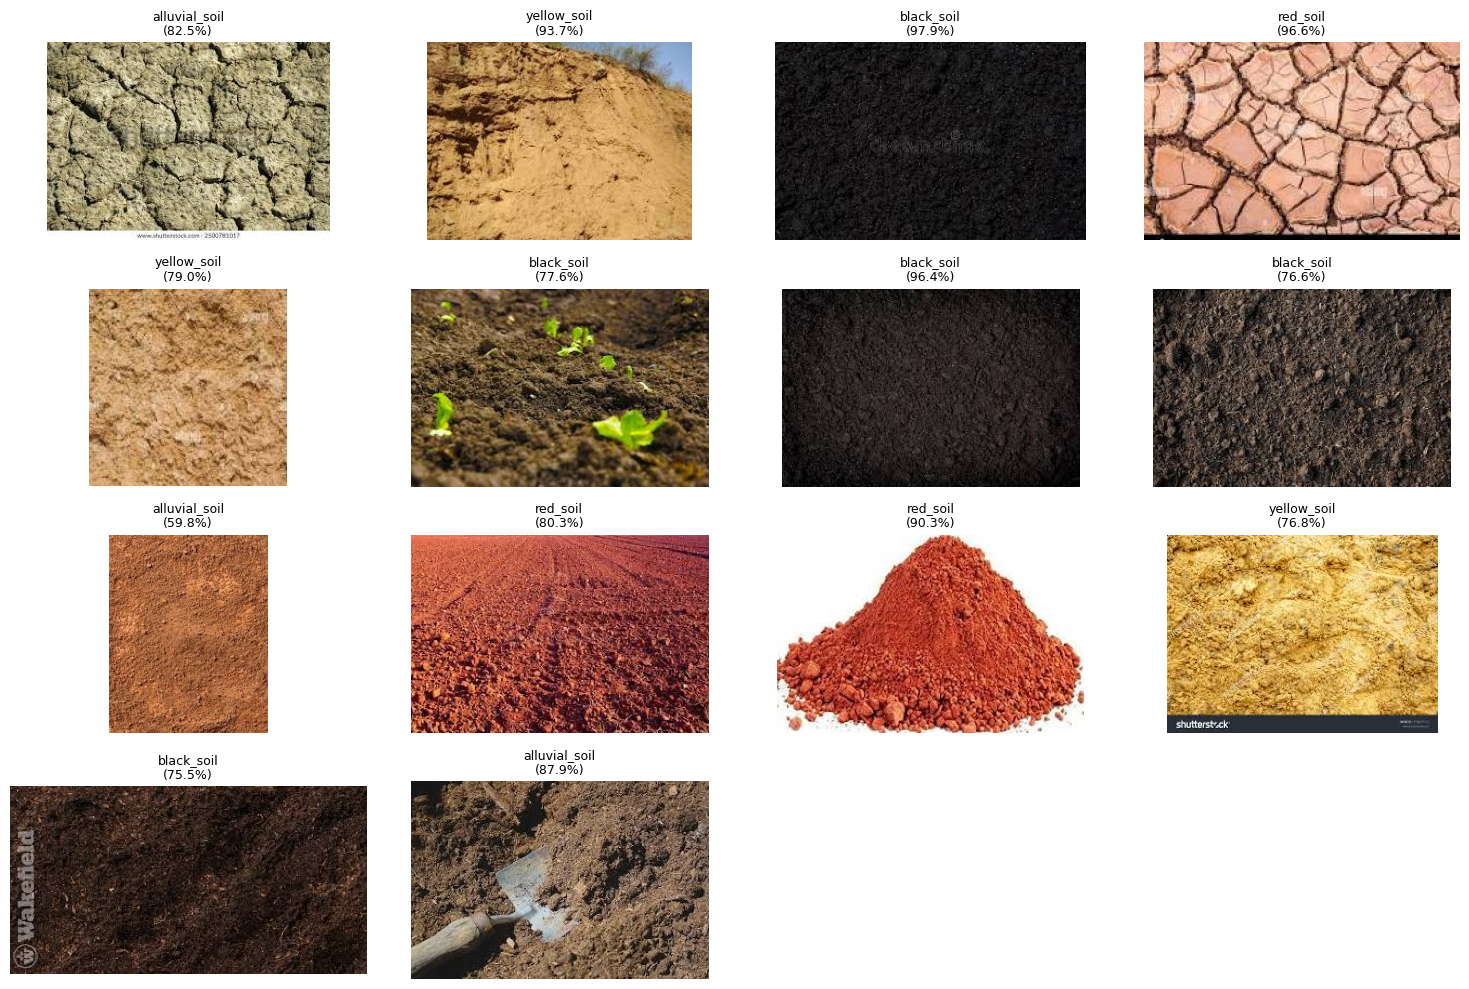

In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1️⃣ Load saved model
model = load_model("/content/drive/MyDrive/my_model.h5")

# 2️⃣ Path to unseen images folder
unseen_dir = "/content/drive/MyDrive/unseen_data"

# 3️⃣ Class labels (same as training order)
class_labels = ['alluvial_soil', 'black_soil', 'clay_soil', 'loamy_soil',
                'peat_soil', 'red_soil', 'sandy_soil', 'yellow_soil']

# 4️⃣ Preprocessing Function
def preprocess_img(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

# 5️⃣ Get all image paths
images = [os.path.join(unseen_dir, fname) for fname in os.listdir(unseen_dir)
          if fname.lower().endswith(('.jpg', '.jpeg', '.png'))]

print(f"✅ Total Unseen Images Found: {len(images)}")

# 6️⃣ Predict and Display
plt.figure(figsize=(15, 10))
for i, img_path in enumerate(images):
    img_array = preprocess_img(img_path)
    preds = model.predict(img_array)

    pred_label = class_labels[np.argmax(preds[0])]
    confidence = np.max(preds[0]) * 100

    plt.subplot(4, 4, i+1)  # 14 images → 4x4 grid enough
    plt.imshow(image.load_img(img_path))
    plt.axis('off')
    plt.title(f"{pred_label}\n({confidence:.1f}%)", fontsize=9)

plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 38 variables whereas the saved optimizer has 74 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


✅ Total Unseen Images Found: 14
1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


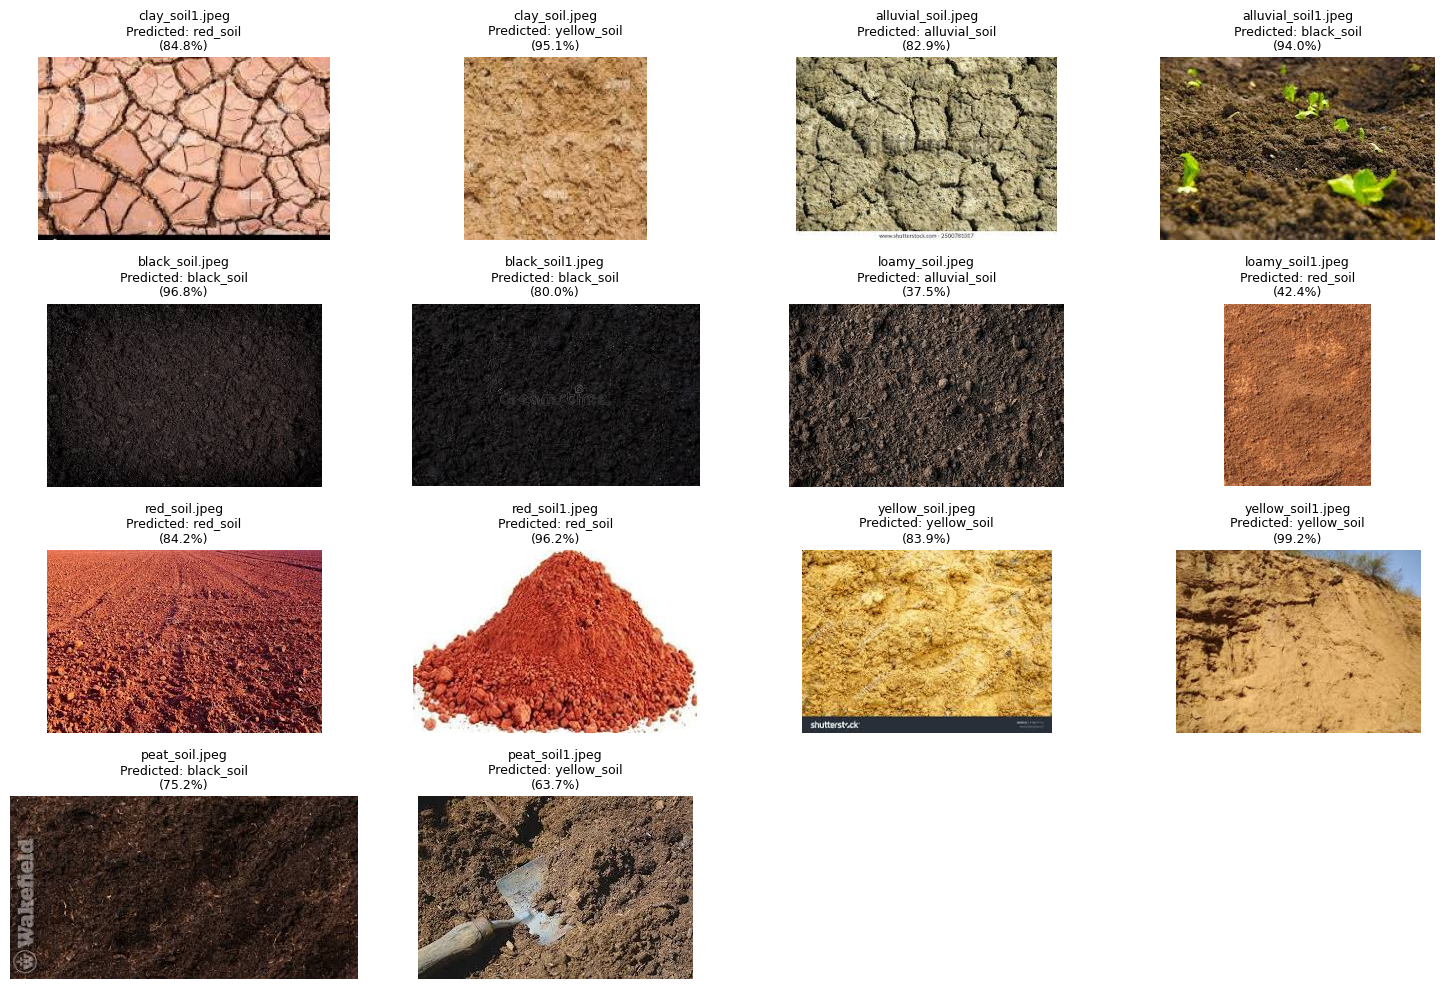

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# Load your model
model = load_model('/content/drive/MyDrive/final_soil_mobilenetv2_finetuned.keras')

# Folder containing unseen test images
unseen_dir = '/content/drive/MyDrive/unseen_data'

# Class labels (same order as training)
class_labels = ['alluvial_soil', 'black_soil', 'clay_soil', 'loamy_soil',
                'peat_soil', 'red_soil', 'sandy_soil', 'yellow_soil']

def preprocess_img(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    return np.expand_dims(img_array, axis=0)

# List all image files
image_files = [f for f in os.listdir(unseen_dir) if f.lower().endswith(('jpg','png','jpeg'))]

print(f"✅ Total Unseen Images Found: {len(image_files)}")

plt.figure(figsize=(15, 10))

for i, fname in enumerate(image_files):
    img_path = os.path.join(unseen_dir, fname)

    img_array = preprocess_img(img_path)
    preds = model.predict(img_array)
    pred_label = class_labels[np.argmax(preds[0])]
    confidence = np.max(preds[0]) * 100

    # Show image with prediction result
    plt.subplot(4, 4, i+1)
    plt.imshow(image.load_img(img_path))
    plt.axis('off')
    plt.title(f"{fname}\nPredicted: {pred_label}\n({confidence:.1f}%)", fontsize=9)

plt.tight_layout()
plt.show()
